# **Proyecto Final - Predicción de enfermedad cardíaca mediante aprendizaje automático a partir de variables clínicas de pacientes**

---

**Autor:** Juan Fernando Linares Díaz

**Descripción general:** Este proyecto desarrolla un modelo de aprendizaje automático supervisado que predice la presencia de enfermedad cardíaca a partir de variables clínicas y demográficas de pacientes. Como resultado se espera identificar qué variables clínicas pesan más en la predicción y medir qué tan bien puede un modelo basado en datos básicos distinguir entre pacientes con y sin enfermedad cardíaca.




In [2]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ruta_csv = '/content/drive/MyDrive/Proyecto - Caso Real/Dataset_pacientes_cardiacos.csv'
df = pd.read_csv(ruta_csv)

Mounted at /content/drive


# **Parte 1: Definición del problema**


---


1.   **Contexto:** Las enfermedades cardiovasculares son una de las principales causas de muerte en el mundo, y también en Colombia. Detectarlas a tiempo mejora el pronóstico y reduce costos de atención. En la práctica, el médico combina síntomas (tipo de dolor torácico) con mediciones objetivas (presión arterial, colesterol, frecuencia cardíaca máxima, depresión del segmento ST en la prueba de esfuerzo). Un modelo de ML puede aprender de casos previos qué combinaciones se asocian con la enfermedad y servir como apoyo a la decisión clínica, nunca como reemplazo del diagnóstico.

2. **Objetivo del proyecto:** Construir, entrenar y evaluar un modelo de clasificación que prediga la presencia de enfermedad cardíaca a partir de variables demográficas y clínicas. Para lograrlo, se explora el dataset, se identifica qué variables se relacionan más con la enfermedad y se preparan los datos para el modelo (limpieza, codificación y escalado).

3. **Pregunta de investigación:** ¿Es posible predecir la presencia de enfermedad cardíaca con una sensibilidad (recall) aceptable usando variables clínicas básicas como edad, sexo, tipo de dolor torácico, presión arterial, colesterol, frecuencia cardíaca máxima, depresión del ST y angina inducida por ejercicio? ¿Cuáles de ellas aportan más al resultado?

4. **Justificación del dataset:** Es un dataset que incluye variables clínicas de cardiología, tiene un tamaño manejable, tiene una mezcla de tipos de variables (numéricas y categóricas) y finalmente es un dataset con imperfecciones reales para trabajar, hay valores nulos, registros duplicados, etiquetas inconsistentes y valores atípicos, lo que uno se puede encontrar en el mundo real.





# **Parte 2: Comprensión de los datos**

---



In [3]:
print("Cantidad de columnas:",df.shape[1])
print("Cantidad de filas:",df.shape[0])
print("")
print(df.head())
print(df.info())


Cantidad de columnas: 10
Cantidad de filas: 1020

   Patient_ID   Age  Gender   Chest_Pain_Type  Resting_BP_mmHg  \
0       524.0  87.0     NaN               NaN       151.343081   
1       603.0  66.0    male               NaN       101.214098   
2       527.0  87.0  FEMALE   Atypical Angina       150.354093   
3        32.0  87.0  FEMALE  Non-Anginal Pain       124.865389   
4       617.0  45.0     NaN    Typical Angina       112.437303   

   Cholesterol_mg/dl  Max_Heart_Rate  ST_Depression Exercise_Induced_Angina  \
0         162.378238      162.287641       2.801430                     Yes   
1         218.380992      155.846201       0.182318                      No   
2         248.765623      195.335192       0.875113                     yes   
3                NaN      180.730370       0.300505                     yes   
4         211.572296      121.968906            NaN                      No   

  Heart_Disease  
0          zero  
1          zero  
2             1  
3     

# **Parte 3 - Análisis Exploratorio de Datos (EDA)**

---


1.   Identificación de valores nulos
2.   Valores duplicados
3.   Estadísticas descriptivas
4.   Detección de valores atípicos
5.   Hallazgos principales





In [4]:
# Identificación de nulos

print("Valores nulos:")
print(df.isnull().sum())

Valores nulos:
Patient_ID                  15
Age                         15
Gender                     216
Chest_Pain_Type            222
Resting_BP_mmHg             16
Cholesterol_mg/dl           15
Max_Heart_Rate              16
ST_Depression               25
Exercise_Induced_Angina    219
Heart_Disease              238
dtype: int64


In [5]:
# Identificación de duplicados

print("Cantidad de duplicados:", df.duplicated().sum())

Cantidad de duplicados: 20


In [6]:
# Estadísticas descriptivas

print(df.describe().round(2))

       Patient_ID  Resting_BP_mmHg  Cholesterol_mg/dl  Max_Heart_Rate  \
count     1005.00          1004.00            1005.00         1004.00   
mean       501.48           121.97             208.59          149.89   
std        288.66            18.30              85.67           26.98   
min          1.00            74.71              50.44           74.81   
25%        255.00           110.59             164.55          132.83   
50%        501.00           120.50             201.72          149.95   
75%        752.00           130.90             234.77          166.47   
max       1000.00           237.91             976.73          297.13   

       ST_Depression  
count         995.00  
mean            0.99  
std             0.99  
min            -2.18  
25%             0.34  
50%             0.98  
75%             1.66  
max             4.11  


**Hallazgos principales**

- **Tamaño y estructura:** el dataset original tiene 1020 filas y 10 columnas (5 numéricas y 5 de tipo texto; `Age` llega como texto).
- **Nulos:** `Gender`, `Chest_Pain_Type`, `Exercise_Induced_Angina` y `Heart_Disease` tienen entre 216 y 238 nulos (≈ 21 % a 23 %). Las demás columnas, incluida `Patient_ID`, tienen entre 15 y 25 (≈ 1,5 % a 2,5 %).
- **Duplicados:** hay 20 registros duplicados.
- **Etiquetas inconsistentes:** `Gender` (male, Female, Male, FEMALE) y `Exercise_Induced_Angina` (Yes, yes, No, NO) mezclan mayúsculas y minúsculas, y `Heart_Disease` mezcla números y texto (por ejemplo `zero`, `one` y `1`).
- **Valores atípicos:** colesterol hasta 977 mg/dl, frecuencia cardíaca máxima de 297 lpm y presión arterial de hasta 238 mmHg; su tratamiento se explica en la Parte 4.

# **Parte 4: Preparación de los datos**

---



1.   Limpieza de datos
2.   Tratamiento de los duplicados y valores nulos
3.   Escalamiento o normalización
4.   Visualizaciones relevantes
5.   Codificación de variables categóricas
6.   División entrenamiento/prueba



In [7]:
# Se borran los duplicados

df = df.drop_duplicates()

# Se validan los duplicados

print("Cantidad de duplicados:", df.duplicated().sum())

Cantidad de duplicados: 0


In [8]:
df['Age'].value_counts()

,count
Age,
87.0,27
62.0,26
89.0,25
64.0,24
61.0,23
...,...
unknown,10
85.0,10
63.0,9


In [9]:
# Conversión de columnas al tipo de dato correcto
# Age trae 10 valores escritos como 'unknown' (ver value_counts de arriba): con errors='coerce' pasan a nulos y se imputan más abajo con la mediana

df = df.round(2)
df['Age'] = pd.to_numeric(df['Age'], errors='coerce').round().astype('Int64')

df.isnull().sum()

,0
Patient_ID,15
Age,25
Gender,213
Chest_Pain_Type,220
Resting_BP_mmHg,15
Cholesterol_mg/dl,15
Max_Heart_Rate,15
ST_Depression,25
Exercise_Induced_Angina,217
Heart_Disease,231


In [10]:
df['Heart_Disease'].value_counts()

,count
Heart_Disease,
zero,202
one,201
1,195
0,171


In [11]:

df['Heart_Disease'] = df['Heart_Disease'].replace({
    'zero' : '0' ,
    'one': '1',
})

df['Heart_Disease'] = pd.to_numeric(df['Heart_Disease'], errors='coerce').round().astype('Int64')

df['Heart_Disease'].value_counts()


,count
Heart_Disease,
1,396
0,373


In [12]:
# Normalizar etiquetas en las columnas

print(df['Gender'].value_counts())
print("")
print(df['Chest_Pain_Type'].value_counts())
print("")
print(df['Exercise_Induced_Angina'].value_counts())


Gender
male      207
Female    205
Male      197
FEMALE    178
Name: count, dtype: int64

Chest_Pain_Type
Asymptomatic        220
Atypical Angina     205
Typical Angina      190
Non-Anginal Pain    165
Name: count, dtype: int64

Exercise_Induced_Angina
Yes    229
yes    200
No     179
NO     175
Name: count, dtype: int64


In [13]:
df['Gender'] = df['Gender'].str.strip().str.title()
df['Chest_Pain_Type'] = df['Chest_Pain_Type'].str.strip().str.title()
df['Exercise_Induced_Angina'] = df['Exercise_Induced_Angina'].str.strip().str.title()

print(df['Gender'].value_counts())
print("")
print(df['Chest_Pain_Type'].value_counts())
print("")
print(df['Exercise_Induced_Angina'].value_counts())

Gender
Male      404
Female    383
Name: count, dtype: int64

Chest_Pain_Type
Asymptomatic        220
Atypical Angina     205
Typical Angina      190
Non-Anginal Pain    165
Name: count, dtype: int64

Exercise_Induced_Angina
Yes    429
No     354
Name: count, dtype: int64


In [14]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, 0 to 1019
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Patient_ID               985 non-null    float64
 1   Age                      975 non-null    Int64  
 2   Gender                   787 non-null    object 
 3   Chest_Pain_Type          780 non-null    object 
 4   Resting_BP_mmHg          985 non-null    float64
 5   Cholesterol_mg/dl        985 non-null    float64
 6   Max_Heart_Rate           985 non-null    float64
 7   ST_Depression            975 non-null    float64
 8   Exercise_Induced_Angina  783 non-null    object 
 9   Heart_Disease            769 non-null    Int64  
dtypes: Int64(2), float64(5), object(3)
memory usage: 87.9+ KB
None


In [15]:
# Manejo de valores nulos

df.isnull().sum()

,0
Patient_ID,15
Age,25
Gender,213
Chest_Pain_Type,220
Resting_BP_mmHg,15
Cholesterol_mg/dl,15
Max_Heart_Rate,15
ST_Depression,25
Exercise_Induced_Angina,217
Heart_Disease,231


In [16]:
# Se borran los nulos de la columna 'Heart_Disease' - Es una variable importante donde no puedo inventarme esta respuesta

df = df.dropna(subset=['Heart_Disease'])


In [17]:
df.isnull().sum()

,0
Patient_ID,12
Age,20
Gender,160
Chest_Pain_Type,175
Resting_BP_mmHg,11
Cholesterol_mg/dl,10
Max_Heart_Rate,13
ST_Depression,19
Exercise_Induced_Angina,169
Heart_Disease,0


In [18]:
# En las columnas 'Chest_Pain_Type' - 'Exercise_Induced_Angina' y 'Gender' a los nulos se llenan con 'Desconocido' ('Unknown')

df['Chest_Pain_Type'] = df['Chest_Pain_Type'].fillna('Unknown')
df['Exercise_Induced_Angina'] = df['Exercise_Induced_Angina'].fillna('Unknown')
df['Gender'] = df['Gender'].fillna('Unknown')

In [19]:
# Prueba
df.loc[(df['Chest_Pain_Type'] == 'Unknown') & (df['Heart_Disease'] == 1)]

,Patient_ID,Age,Gender,Chest_Pain_Type,Resting_BP_mmHg,Cholesterol_mg/dl,Max_Heart_Rate,ST_Depression,Exercise_Induced_Angina,Heart_Disease
12,676.0,41,Female,Unknown,114.19,170.54,172.51,1.22,Yes,1
21,NaN,57,Unknown,Unknown,148.06,217.34,171.82,0.83,No,1
24,529.0,<NA>,Male,Unknown,117.15,248.92,156.96,1.22,No,1
29,721.0,53,Male,Unknown,122.40,272.55,122.70,-0.10,No,1
37,590.0,82,Unknown,Unknown,128.77,343.42,172.30,0.16,Unknown,1
...,...,...,...,...,...,...,...,...,...,...
994,414.0,67,Male,Unknown,111.26,216.08,134.18,0.80,No,1
1000,131.0,53,Unknown,Unknown,97.43,139.84,123.94,-0.69,No,1
1001,664.0,72,Unknown,Unknown,126.32,220.82,175.15,0.74,Unknown,1
1009,467.0,<NA>,Male,Unknown,81.56,252.44,138.63,-0.58,Yes,1


In [20]:
df['Chest_Pain_Type'].value_counts()

,count
Chest_Pain_Type,
Unknown,175
Asymptomatic,170
Atypical Angina,151
Typical Angina,141
Non-Anginal Pain,132


In [21]:
print(df.isnull().sum())
print(df.describe().round(2))

Patient_ID                 12
Age                        20
Gender                      0
Chest_Pain_Type             0
Resting_BP_mmHg            11
Cholesterol_mg/dl          10
Max_Heart_Rate             13
ST_Depression              19
Exercise_Induced_Angina     0
Heart_Disease               0
dtype: int64
       Patient_ID    Age  Resting_BP_mmHg  Cholesterol_mg/dl  Max_Heart_Rate  \
count      757.00  749.0           758.00             759.00          756.00   
mean       500.41  60.09           121.70             207.45          149.70   
std        290.84  17.47            18.38              75.85           27.28   
min          1.00   30.0            75.89              50.44           74.81   
25%        249.00   46.0           110.30             165.24          131.88   
50%        492.00   61.0           120.10             202.07          150.08   
75%        760.00   76.0           130.78             234.76          166.38   
max       1000.00   89.0           237.91      

In [22]:
# Nulos de la columna edad, equivalen casi al 2,5% del total de los registros, es un efecto muy pequeño y el rango de edad es de 30 - 89
# Entonces usar la mediana es una opción segura, es un valor neutro para un 2,5% de filas.

df['Age'] = df['Age'].fillna(df['Age'].median())

In [23]:
df.isnull().sum()

,0
Patient_ID,12
Age,0
Gender,0
Chest_Pain_Type,0
Resting_BP_mmHg,11
Cholesterol_mg/dl,10
Max_Heart_Rate,13
ST_Depression,19
Exercise_Induced_Angina,0
Heart_Disease,0


In [24]:
# Para las columnas 'Resting_BP_mmHg', 'Cholesterol_mg/dl',  'Max_Heart_Rate' y 'ST_Depression' lo mejor para conservar el tamaño de la muestra
# Es usar la mediana afecta muy poco. Son 10 a 19 nulos por columna (1.3 % a 2.5 % aprox).

df['Resting_BP_mmHg'] = df['Resting_BP_mmHg'].fillna(df['Resting_BP_mmHg'].median())
df['Cholesterol_mg/dl'] = df['Cholesterol_mg/dl'].fillna(df['Cholesterol_mg/dl'].median())
df['Max_Heart_Rate'] = df['Max_Heart_Rate'].fillna(df['Max_Heart_Rate'].median())
df['ST_Depression'] = df['ST_Depression'].fillna(df['ST_Depression'].median())

In [25]:
df.isnull().sum()

# Los nulos de 'Patient_ID' se dejan así porque para el modelado no se requiere esa columna

,0
Patient_ID,12
Age,0
Gender,0
Chest_Pain_Type,0
Resting_BP_mmHg,0
Cholesterol_mg/dl,0
Max_Heart_Rate,0
ST_Depression,0
Exercise_Induced_Angina,0
Heart_Disease,0


In [26]:
print("Despues del manejo de nulos, quedan: ")
print("Columnas:", df.shape[1])
print("Filas:", df.shape[0])

Despues del manejo de nulos, quedan: 
Columnas: 10
Filas: 769


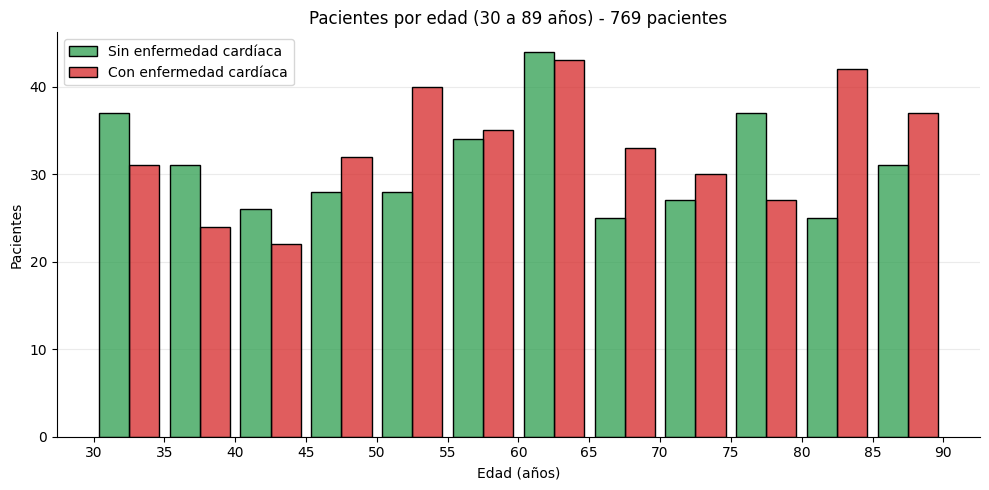

In [27]:
# Visualización relevante - Pacientes por edad según presencia de enfermedad cardíaca
# (etiqueta se usa solo para graficar; no se agrega columna al df para no filtrar la variable objetivo)
etiqueta = df['Heart_Disease'].map({0: 'Sin enfermedad cardíaca', 1: 'Con enfermedad cardíaca'})
orden = ['Sin enfermedad cardíaca', 'Con enfermedad cardíaca']
colores = {'Sin enfermedad cardíaca': '#2e9e4f', 'Con enfermedad cardíaca': '#d62728'}

tmp = pd.DataFrame({'Age': df['Age'].astype(int), 'Estado': etiqueta})

cortes = list(range(30, 95, 5))   # rangos de 5 años

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=tmp, x='Age', hue='Estado', hue_order=orden, palette=colores,
             multiple='dodge', bins=cortes, shrink=0.85, ax=ax)
ax.set_xticks(cortes)
ax.set_title(f'Pacientes por edad (30 a 89 años) - {len(df)} pacientes')
ax.set_xlabel('Edad (años)')
ax.set_ylabel('Pacientes')
ax.get_legend().set_title('')
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
sns.despine()
plt.tight_layout(); plt.show()

Se evidencia qué en la muestra después de los 80 años es más frecuente o más problable sufrir de alguna enfermedad del corazón.

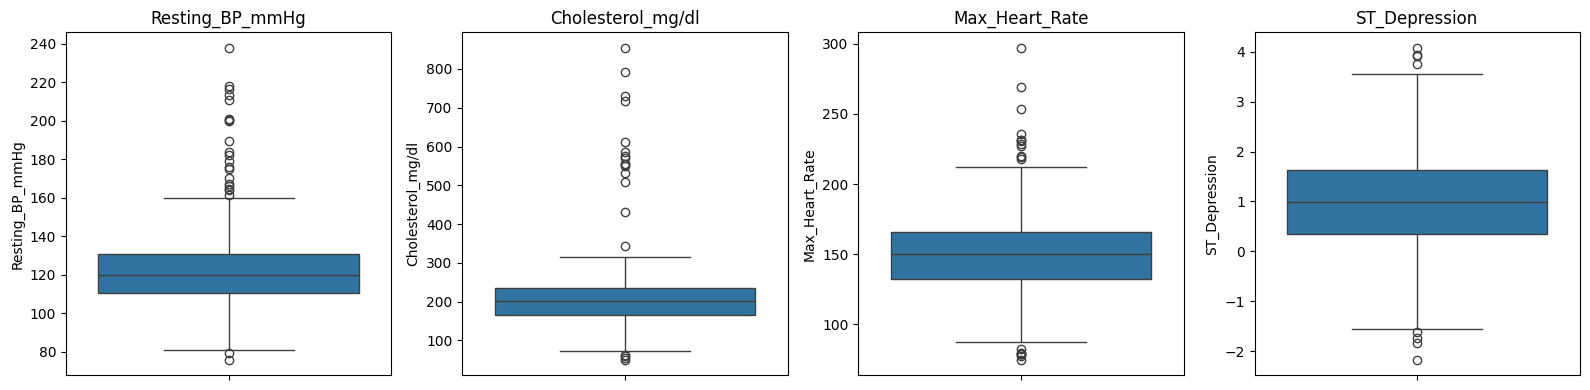

In [28]:
# - Visualización relevante - Valores atípicos

cols_num = ['Resting_BP_mmHg', 'Cholesterol_mg/dl', 'Max_Heart_Rate', 'ST_Depression']

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, cols_num):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

In [29]:
print(df.loc[df["Max_Heart_Rate"] > 220])

      Patient_ID  Age   Gender   Chest_Pain_Type  Resting_BP_mmHg  \
65          31.0   41     Male    Typical Angina           106.44   
404        809.0   67     Male    Typical Angina           121.14   
421        577.0   82   Female  Non-Anginal Pain            92.00   
435        888.0   32   Female           Unknown           120.82   
440        396.0   50  Unknown           Unknown           119.86   
499        337.0   64   Female  Non-Anginal Pain           110.38   
656        230.0   42     Male      Asymptomatic           144.23   
798        283.0   61   Female      Asymptomatic           159.67   
893         65.0   55   Female   Atypical Angina           124.98   
1007       331.0   54  Unknown           Unknown           110.60   

      Cholesterol_mg/dl  Max_Heart_Rate  ST_Depression  \
65               550.58          231.70           2.47   
404              854.36          269.57           0.96   
421              716.90          235.37           1.60   
435     

In [30]:
print(df.loc[df["Cholesterol_mg/dl"] > 600])

     Patient_ID  Age  Gender   Chest_Pain_Type  Resting_BP_mmHg  \
381       552.0   76    Male   Atypical Angina           100.60   
404       809.0   67    Male    Typical Angina           121.14   
421       577.0   82  Female  Non-Anginal Pain            92.00   
758       736.0   49  Female    Typical Angina           106.14   
798       283.0   61  Female      Asymptomatic           159.67   

     Cholesterol_mg/dl  Max_Heart_Rate  ST_Depression Exercise_Induced_Angina  \
381             791.83          188.63           1.77                     Yes   
404             854.36          269.57           0.96                      No   
421             716.90          235.37           1.60                     Yes   
758             611.72          171.27          -0.51                 Unknown   
798             731.41          227.25           0.54                      No   

     Heart_Disease  
381              0  
404              1  
421              0  
758              0  
798  

### Tratamiento de valores atípicos

**Criterio.** Se distinguió entre valores *fisiológicamente implausibles* (errores de registro) y valores *extremos pero clínicamente posibles*. Los primeros se reemplazan; los segundos se conservan, porque pueden ser casos clínicos reales y aportar información al modelo.

**Valores modificados** (se convierten en nulos y se imputan con la mediana):

- **(Frecuencia cardiaca Max) Max_Heart_Rate > 220 lpm** (10 registros, máximo 297). La frecuencia cardíaca máxima en una prueba de esfuerzo se estima con la regla 220 − edad (≈ 190 lpm a los 30 años y ≈ 140 lpm a los 80). Valores de 220 a 297 lpm son fisiológicamente implausibles para esta medición y solo los explicaría una arritmia, por lo que se tratan como errores de registro.
- **Cholesterol_mg/dl > 600 mg/dl** (5 registros, máximo 854). Un colesterol total tan alto es extremadamente raro en adultos y está muy alejado del resto de la distribución (el 75 % de los pacientes está por debajo de 235 mg/dl).

**Por qué imputar con la mediana y no eliminar filas.** (i) El dataset es pequeño (769 filas). (ii) En total se afectan 12 registros distintos (≈ 1,6 %) y en cada uno solo se modifican una o dos columnas, por lo que el resto de su información sigue siendo válida. (iii) La mediana es robusta a valores extremos.

**Valores conservados:**

- **Resting_BP_mmHg: (Presión arterial en reposo)** las presiones elevadas (hasta 238 mmHg) son extremas pero posibles en una crisis hipertensiva, y la presión arterial es una variable clínicamente relevante para el diagnóstico.
- **ST_Depression (−2,2 a 4,1):** el rango es compatible con lo observado en pruebas de esfuerzo; los valores negativos pueden corresponder a elevación del segmento ST.
- **Cholesterol_mg/dl (Colesterol en la sangre) (valores bajos, mínimo ≈ 50 mg/dl):** son poco comunes pero posibles, y no se alejan del resto de la distribución como los valores altos. Se conservan.


In [31]:
df.loc[df["Max_Heart_Rate"] > 220, "Max_Heart_Rate"] = np.nan
df.loc[df["Cholesterol_mg/dl"] > 600, "Cholesterol_mg/dl"] = np.nan

In [32]:
# Los valores atípicos que se marcaron como NaN se imputan con la mediana (igual que el resto de nulos numéricos)
# La mediana se calcula sin los outliers, porque ya fueron convertidos a NaN

print("Nulos antes:")
print(df[['Max_Heart_Rate', 'Cholesterol_mg/dl']].isnull().sum())

df['Max_Heart_Rate'] = df['Max_Heart_Rate'].fillna(df['Max_Heart_Rate'].median())
df['Cholesterol_mg/dl'] = df['Cholesterol_mg/dl'].fillna(df['Cholesterol_mg/dl'].median())

print("\nNulos después (sin contar Patient_ID, que no se usa en el modelo):")
print(df.drop(columns='Patient_ID').isnull().sum())

print()
print(df[['Max_Heart_Rate', 'Cholesterol_mg/dl']].describe().round(2))

Nulos antes:
Max_Heart_Rate       10
Cholesterol_mg/dl     5
dtype: int64

Nulos después (sin contar Patient_ID, que no se usa en el modelo):
Age                        0
Gender                     0
Chest_Pain_Type            0
Resting_BP_mmHg            0
Cholesterol_mg/dl          0
Max_Heart_Rate             0
ST_Depression              0
Exercise_Induced_Angina    0
Heart_Disease              0
dtype: int64

       Max_Heart_Rate  Cholesterol_mg/dl
count          769.00             769.00
mean           148.50             203.88
std             24.72              61.39
min             74.81              50.44
25%            132.38             166.61
50%            150.08             202.07
75%            164.61             233.95
max            219.38             585.31


In [33]:
# Codificación de variables categóricas (One-Hot Encoding)
# Gender, Chest_Pain_Type y Exercise_Induced_Angina son nominales (no tienen un orden natural),
# por eso se usa one-hot
# Heart_Disease ya es 0/1 y Age y las medidas clínicas ya son numéricas, así que no se tocan.
# Se guarda en un DataFrame nuevo (df_modelo) para no alterar df.

cols_categoricas = ['Gender', 'Chest_Pain_Type', 'Exercise_Induced_Angina']

df_modelo = pd.get_dummies(df, columns=cols_categoricas, dtype=int)

print("Columnas antes:", df.shape[1], "| después:", df_modelo.shape[1])
print("Columnas de tipo texto que quedan:", df_modelo.select_dtypes(include='object').columns.tolist())
print()

cols_nuevas = df_modelo.filter(regex='^(Gender|Chest_Pain_Type|Exercise_Induced_Angina)_').columns
print(df_modelo[cols_nuevas].sum())
print(df_modelo.shape)
display(df_modelo.head())

Columnas antes: 10 | después: 18
Columnas de tipo texto que quedan: []

Gender_Female                       306
Gender_Male                         303
Gender_Unknown                      160
Chest_Pain_Type_Asymptomatic        170
Chest_Pain_Type_Atypical Angina     151
Chest_Pain_Type_Non-Anginal Pain    132
Chest_Pain_Type_Typical Angina      141
Chest_Pain_Type_Unknown             175
Exercise_Induced_Angina_No          276
Exercise_Induced_Angina_Unknown     169
Exercise_Induced_Angina_Yes         324
dtype: int64
(769, 18)


,Patient_ID,Age,Resting_BP_mmHg,Cholesterol_mg/dl,Max_Heart_Rate,ST_Depression,Heart_Disease,Gender_Female,Gender_Male,Gender_Unknown,Chest_Pain_Type_Asymptomatic,Chest_Pain_Type_Atypical Angina,Chest_Pain_Type_Non-Anginal Pain,Chest_Pain_Type_Typical Angina,Chest_Pain_Type_Unknown,Exercise_Induced_Angina_No,Exercise_Induced_Angina_Unknown,Exercise_Induced_Angina_Yes
0,524.0,87,151.34,162.38,162.29,2.80,0,0,0,1,0,0,0,0,1,0,0,1
1,603.0,66,101.21,218.38,155.85,0.18,0,0,1,0,0,0,0,0,1,1,0,0
2,527.0,87,150.35,248.77,195.34,0.88,1,1,0,0,0,1,0,0,0,0,0,1
4,617.0,45,112.44,211.57,121.97,0.98,1,0,0,1,0,0,0,1,0,1,0,0
6,445.0,89,130.06,252.09,164.89,1.89,1,1,0,0,1,0,0,0,0,1,0,0


## Preparación final para el modelado

Antes de entrenar se hacen cuatro pasos sobre `df_modelo`:

1. Se descarta `Patient_ID` (solo identifica al paciente, no es una variable clínica y tiene nulos) y `Age` y `Heart_Disease` pasan a `int64` estándar, porque ya no tienen nulos.
2. Se separan las variables predictoras (`X`) del objetivo (`y = Heart_Disease`).
3. Se divide en entrenamiento (80 %) y prueba (20 %), de forma estratificada para conservar la proporción de pacientes con y sin enfermedad.
4. Se escalan solo las 5 variables numéricas con `StandardScaler`, ajustado únicamente con el conjunto de entrenamiento para no filtrar información de la prueba. Las variables dummy no se escalan.

La regresión logística usará los datos escalados (`X_train_esc`, `X_test_esc`) y el random forest puede usar los datos sin escalar (`X_train`, `X_test`), porque no depende de la escala.

In [34]:
# 1. Se descarta Patient_ID y se pasan Age y Heart_Disease a int64 estándar

df_modelo = df_modelo.drop(columns='Patient_ID')

df_modelo['Age'] = df_modelo['Age'].astype('int64')
df_modelo['Heart_Disease'] = df_modelo['Heart_Disease'].astype('int64')

print("Filas y columnas:", df_modelo.shape)
print("Nulos en total:", df_modelo.isnull().sum().sum())
print(df_modelo.dtypes)

Filas y columnas: (769, 17)
Nulos en total: 0
Age                                   int64
Resting_BP_mmHg                     float64
Cholesterol_mg/dl                   float64
Max_Heart_Rate                      float64
ST_Depression                       float64
Heart_Disease                         int64
Gender_Female                         int64
Gender_Male                           int64
Gender_Unknown                        int64
Chest_Pain_Type_Asymptomatic          int64
Chest_Pain_Type_Atypical Angina       int64
Chest_Pain_Type_Non-Anginal Pain      int64
Chest_Pain_Type_Typical Angina        int64
Chest_Pain_Type_Unknown               int64
Exercise_Induced_Angina_No            int64
Exercise_Induced_Angina_Unknown       int64
Exercise_Induced_Angina_Yes           int64
dtype: object


In [35]:
# 2 y 3. Separar predictoras (X) y objetivo (y) y dividir en entrenamiento y prueba
from sklearn.model_selection import train_test_split

X = df_modelo.drop(columns='Heart_Disease')
y = df_modelo['Heart_Disease']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("\nProporción de enfermedad en y_train:", y_train.mean().round(3))
print("Proporción de enfermedad en y_test: ", y_test.mean().round(3))

Entrenamiento: (615, 16) | Prueba: (154, 16)

Proporción de enfermedad en y_train: 0.515
Proporción de enfermedad en y_test:  0.513


In [36]:
# 4. Escalamiento de las variables numéricas (el scaler se ajusta solo con entrenamiento)
from sklearn.preprocessing import StandardScaler

cols_numericas = ['Age', 'Resting_BP_mmHg', 'Cholesterol_mg/dl', 'Max_Heart_Rate', 'ST_Depression']

scaler = StandardScaler()
X_train_esc = X_train.copy()
X_test_esc = X_test.copy()
X_train_esc[cols_numericas] = scaler.fit_transform(X_train[cols_numericas])
X_test_esc[cols_numericas] = scaler.transform(X_test[cols_numericas])

# En entrenamiento la media debe ser ~0 y la desviación ~1
print(X_train_esc[cols_numericas].describe().round(2).loc[['mean', 'std']])
print("\nColumnas finales de X:", list(X_train_esc.columns))

      Age  Resting_BP_mmHg  Cholesterol_mg/dl  Max_Heart_Rate  ST_Depression
mean  0.0              0.0               -0.0             0.0           -0.0
std   1.0              1.0                1.0             1.0            1.0

Columnas finales de X: ['Age', 'Resting_BP_mmHg', 'Cholesterol_mg/dl', 'Max_Heart_Rate', 'ST_Depression', 'Gender_Female', 'Gender_Male', 'Gender_Unknown', 'Chest_Pain_Type_Asymptomatic', 'Chest_Pain_Type_Atypical Angina', 'Chest_Pain_Type_Non-Anginal Pain', 'Chest_Pain_Type_Typical Angina', 'Chest_Pain_Type_Unknown', 'Exercise_Induced_Angina_No', 'Exercise_Induced_Angina_Unknown', 'Exercise_Induced_Angina_Yes']


# **Parte 5: Modelado**


---

1. **Regresión logística 1**, entrenada con los datos escalados (incluye la categoría "Unknown").
2. **Random forest**, entrenado con los datos sin escalar.
3. Evaluación de cada modelo en el conjunto de prueba: accuracy, precision, recall (es la métrica que pide la pregunta de investigación), F1, matriz de confusión y AUC-ROC.
4. **Regresión logística 2**, entrenada con los datos escalados y sin los pacientes que tienen "Unknown" (muestra reducida).
5. **XGBoost**, entrenado con los datos sin escalar.
6. **XGBoost ajustado**, con búsqueda de hiperparámetros por validación cruzada (sección 5.8).
7. Comparación final de los modelos (secciones 5.7 y 5.8) y comparación con validación cruzada repetida y prueba de permutación (sección 5.9).

In [37]:
# 5.1 Regresión logística (datos escalados)
from sklearn.linear_model import LogisticRegression

modelo_lr = LogisticRegression(max_iter=1000, random_state=42)
modelo_lr.fit(X_train_esc, y_train)

# Predicciones sobre el conjunto de prueba (clase y probabilidad de tener enfermedad)
y_pred_lr = modelo_lr.predict(X_test_esc)
y_prob_lr = modelo_lr.predict_proba(X_test_esc)[:, 1]

print("Regresión logística entrenada con", X_train_esc.shape[0], "pacientes y", X_train_esc.shape[1], "variables")

Regresión logística entrenada con 615 pacientes y 16 variables


In [38]:
# 5.2 Random forest (datos sin escalar: los árboles no dependen de la escala)
from sklearn.ensemble import RandomForestClassifier

# Se limita la profundidad y el tamaño mínimo de hoja para reducir el sobreajuste (valores fijados de antemano, sin mirar la prueba)
modelo_rf = RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=10, random_state=42, n_jobs=-1)
modelo_rf.fit(X_train, y_train)

# Predicciones sobre el conjunto de prueba (clase y probabilidad de tener enfermedad)
y_pred_rf = modelo_rf.predict(X_test)
y_prob_rf = modelo_rf.predict_proba(X_test)[:, 1]

print("Random forest entrenado con", X_train.shape[0], "pacientes y", X_train.shape[1], "variables")

Random forest entrenado con 615 pacientes y 16 variables


In [39]:
# 5.3 Evaluación en el conjunto de prueba
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

def metricas(y_real, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_real, y_pred),
        'Precision': precision_score(y_real, y_pred),
        'Recall': recall_score(y_real, y_pred),
        'F1': f1_score(y_real, y_pred),
        'AUC-ROC': roc_auc_score(y_real, y_prob),
    }

# Referencia: "modelo" ingenuo que no aprende nada y predice "con enfermedad" (1) para TODOS los pacientes de prueba.
# Sirve para saber si los modelos aportan algo: un modelo útil debe superar sus métricas.
y_pred_base = np.ones(len(y_test), dtype=int)
y_prob_base = np.full(len(y_test), 0.5)  # misma probabilidad para todos: no distingue entre pacientes

tabla = pd.DataFrame({
    'Regresión logística': metricas(y_test, y_pred_lr, y_prob_lr),
    'Random forest': metricas(y_test, y_pred_rf, y_prob_rf),
    'Referencia (predice "enfermo" a todos)': metricas(y_test, y_pred_base, y_prob_base),
}).T.round(3)

print("Métricas en el conjunto de prueba:")
print(tabla.to_string())

# Explicación de la fila de referencia, con los datos reales de la prueba
n_prueba = len(y_test)
n_enfermos = int(y_test.sum())
n_sanos = n_prueba - n_enfermos
print(f"\nQué es la fila 'Referencia (predice \"enfermo\" a todos)':")
print(f"  Es un modelo ingenuo que no aprende nada: clasifica a los {n_prueba} pacientes de prueba como 'con enfermedad'.")
print(f"  - Accuracy y Precision = {y_test.mean():.3f}: es la proporción real de pacientes con enfermedad ({n_enfermos} de {n_prueba}).")
print(f"  - Recall = 1.000: detecta a los {n_enfermos} enfermos, pero solo porque marca como enfermos también a los {n_sanos} sanos.")
print("  - AUC-ROC = 0.500: asigna la misma probabilidad a todos, así que no distingue entre pacientes.")
print("  Un modelo aporta algo solo si supera a la referencia en accuracy, precision y AUC-ROC,")
print("  es decir, si acierta más que marcar a todos como enfermos. El recall de la referencia no es una meta: es 1.000 sin ningún criterio.")

# Entrenamiento vs prueba (para detectar sobreajuste)
print("\nAUC-ROC: entrenamiento vs prueba")
print("Regresión logística:", round(roc_auc_score(y_train, modelo_lr.predict_proba(X_train_esc)[:, 1]), 3),
      "vs", round(roc_auc_score(y_test, y_prob_lr), 3))
print("Random forest:      ", round(roc_auc_score(y_train, modelo_rf.predict_proba(X_train)[:, 1]), 3),
      "vs", round(roc_auc_score(y_test, y_prob_rf), 3))

Métricas en el conjunto de prueba:
                                        Accuracy  Precision  Recall     F1  AUC-ROC
Regresión logística                        0.494      0.506    0.57  0.536    0.475
Random forest                              0.494      0.506    0.57  0.536    0.482
Referencia (predice "enfermo" a todos)     0.513      0.513    1.00  0.678    0.500

Qué es la fila 'Referencia (predice "enfermo" a todos)':
  Es un modelo ingenuo que no aprende nada: clasifica a los 154 pacientes de prueba como 'con enfermedad'.
  - Accuracy y Precision = 0.513: es la proporción real de pacientes con enfermedad (79 de 154).
  - Recall = 1.000: detecta a los 79 enfermos, pero solo porque marca como enfermos también a los 75 sanos.
  - AUC-ROC = 0.500: asigna la misma probabilidad a todos, así que no distingue entre pacientes.
  Un modelo aporta algo solo si supera a la referencia en accuracy, precision y AUC-ROC,
  es decir, si acierta más que marcar a todos como enfermos. El recall de

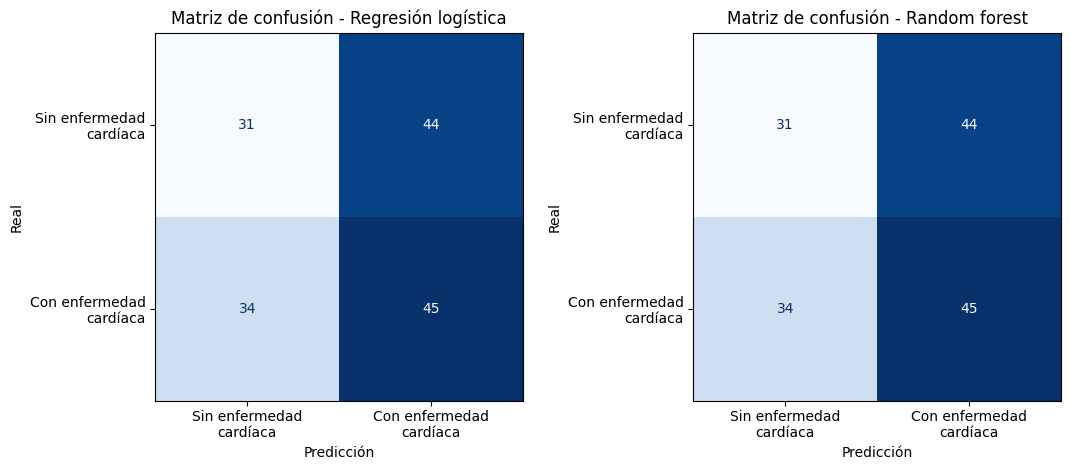

In [40]:
# Matrices de confusión (conjunto de prueba)
etiquetas = ['Sin enfermedad\ncardíaca', 'Con enfermedad\ncardíaca']

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (nombre, y_pred) in zip(axes, [('Regresión logística', y_pred_lr), ('Random forest', y_pred_rf)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=etiquetas).plot(
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Matriz de confusión - {nombre}')
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Real')
plt.tight_layout(); plt.show()

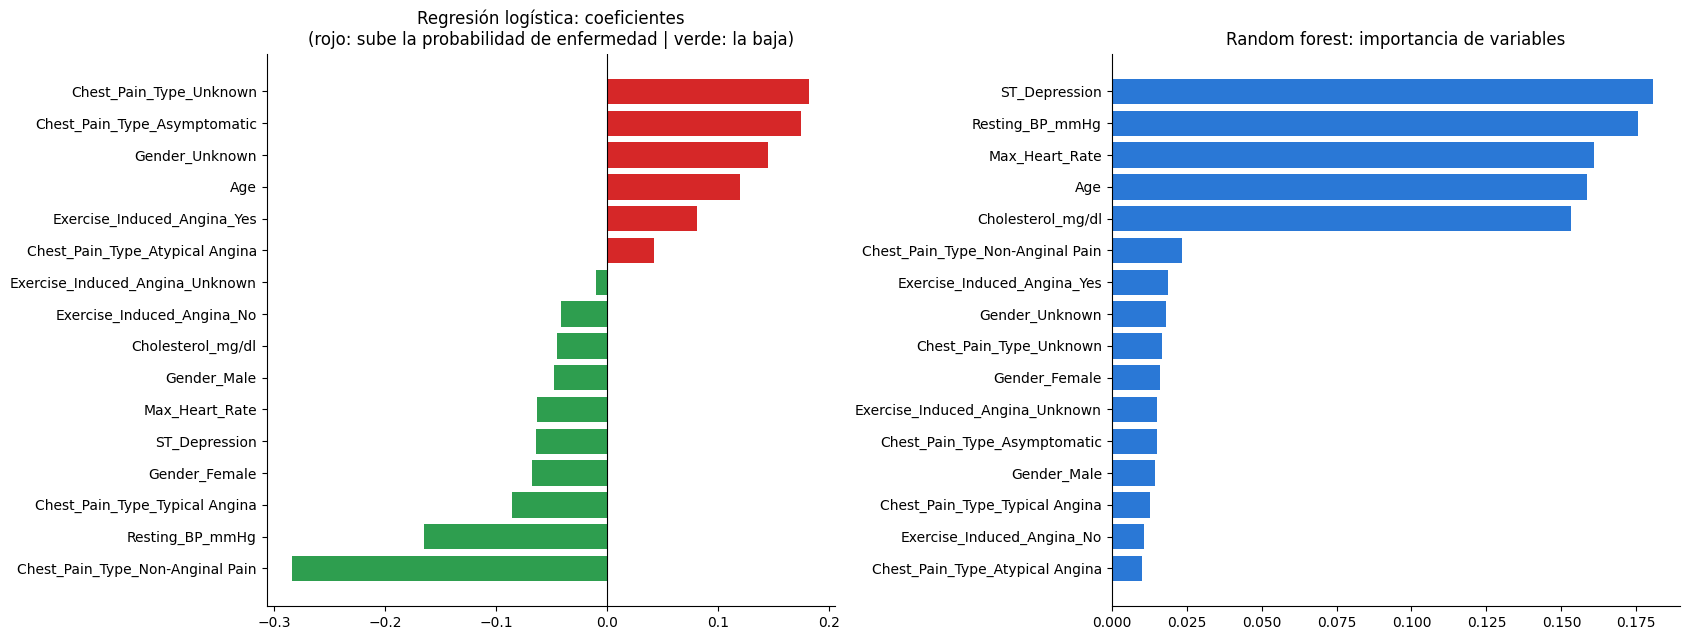

                                  Coef. regresión logística  \
ST_Depression                                        -0.064   
Resting_BP_mmHg                                      -0.165   
Max_Heart_Rate                                       -0.064   
Age                                                   0.120   
Cholesterol_mg/dl                                    -0.045   
Chest_Pain_Type_Non-Anginal Pain                     -0.283   
Exercise_Induced_Angina_Yes                           0.081   
Gender_Unknown                                        0.145   
Chest_Pain_Type_Unknown                               0.182   
Gender_Female                                        -0.068   
Exercise_Induced_Angina_Unknown                      -0.010   
Chest_Pain_Type_Asymptomatic                          0.174   
Gender_Male                                          -0.048   
Chest_Pain_Type_Typical Angina                       -0.086   
Exercise_Induced_Angina_No                           -0

In [41]:
# 5.4 Importancia de variables
imp_lr = pd.Series(modelo_lr.coef_[0], index=X_train_esc.columns).sort_values()
imp_rf = pd.Series(modelo_rf.feature_importances_, index=X_train.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

axes[0].barh(imp_lr.index, imp_lr.values, color=['#d62728' if v > 0 else '#2e9e4f' for v in imp_lr.values])
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title('Regresión logística: coeficientes\n(rojo: sube la probabilidad de enfermedad | verde: la baja)')

axes[1].barh(imp_rf.index, imp_rf.values, color='#2a78d6')
axes[1].set_title('Random forest: importancia de variables')

sns.despine()
plt.tight_layout(); plt.show()

print(pd.DataFrame({'Coef. regresión logística': imp_lr, 'Importancia random forest': imp_rf})
      .sort_values('Importancia random forest', ascending=False).round(3))

## 5.5 Regresión logística 2 (sin variables 'Unknown')

Se deja la regresión logística anterior como **regresión logística 1** y se entrena una **regresión logística 2** sin los pacientes que tienen 'Unknown' en sexo, tipo de dolor torácico o angina inducida (y sin esas tres columnas). Se sabe que la muestra queda mucho más pequeña; el objetivo es solo ver cómo se comporta.

In [42]:
# 5.5 Regresión logística 2 (sin pacientes con valores 'Unknown')
# Se eliminan los pacientes que tienen 'Unknown' en sexo, tipo de dolor torácico o angina inducida
# y se descartan las 3 columnas *_Unknown. La regresión logística 1 (modelo_lr) no se modifica.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

cols_unknown = ['Gender_Unknown', 'Chest_Pain_Type_Unknown', 'Exercise_Induced_Angina_Unknown']

sin_unknown = df_modelo[cols_unknown].sum(axis=1) == 0
df_lr2 = df_modelo.loc[sin_unknown].drop(columns=cols_unknown)

print("Pacientes con algún 'Unknown':", int((~sin_unknown).sum()))
print("Pacientes que quedan para la regresión logística 2:", df_lr2.shape[0], "de", df_modelo.shape[0])
print("Proporción de enfermedad en esta muestra:", df_lr2['Heart_Disease'].mean().round(3))

X2 = df_lr2.drop(columns='Heart_Disease')
y2 = df_lr2['Heart_Disease']
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2
)

# El escalador nuevo se ajusta solo con el entrenamiento de esta muestra reducida
scaler2 = StandardScaler()
X2_train_esc = X2_train.copy()
X2_test_esc = X2_test.copy()
X2_train_esc[cols_numericas] = scaler2.fit_transform(X2_train[cols_numericas])
X2_test_esc[cols_numericas] = scaler2.transform(X2_test[cols_numericas])

modelo_lr2 = LogisticRegression(max_iter=1000, random_state=42)
modelo_lr2.fit(X2_train_esc, y2_train)

y_pred_lr2 = modelo_lr2.predict(X2_test_esc)
y_prob_lr2 = modelo_lr2.predict_proba(X2_test_esc)[:, 1]

print("\nEntrenamiento:", X2_train.shape, "| Prueba:", X2_test.shape)
print("Métricas en la prueba (regresión logística 2):")
print(pd.Series(metricas(y2_test, y_pred_lr2, y_prob_lr2)).round(3).to_string())
print("Referencia (predice 'enfermo' a todos): accuracy =", y2_test.mean().round(3))

# Con una prueba tan pequeña las métricas son muy inestables: se complementa con validación cruzada (5 particiones)
prep2 = ColumnTransformer([('num', StandardScaler(), cols_numericas)], remainder='passthrough')
pipe_lr2 = Pipeline([('prep', prep2), ('lr', LogisticRegression(max_iter=1000, random_state=42))])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
auc_cv = cross_val_score(pipe_lr2, X2, y2, cv=cv, scoring='roc_auc')
print("\nAUC-ROC en validación cruzada:", auc_cv.mean().round(3), "+/-", auc_cv.std().round(3))

Pacientes con algún 'Unknown': 394
Pacientes que quedan para la regresión logística 2: 375 de 769
Proporción de enfermedad en esta muestra: 0.493

Entrenamiento: (300, 13) | Prueba: (75, 13)
Métricas en la prueba (regresión logística 2):
Accuracy     0.507
Precision    0.500
Recall       0.595
F1           0.543
AUC-ROC      0.517
Referencia (predice 'enfermo' a todos): accuracy = 0.493

AUC-ROC en validación cruzada: 0.548 +/- 0.08


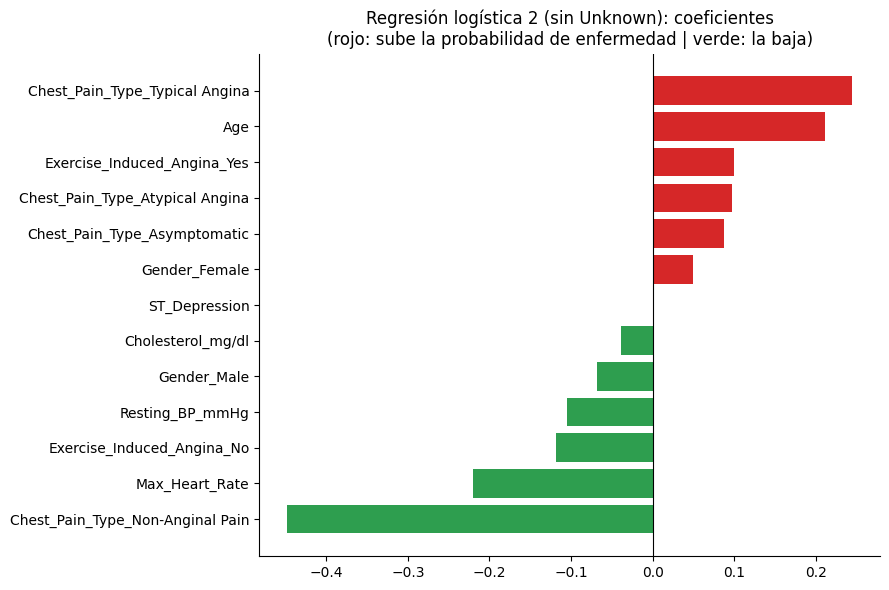

Chest_Pain_Type_Non-Anginal Pain   -0.448
Chest_Pain_Type_Typical Angina      0.244
Max_Heart_Rate                     -0.220
Age                                 0.211
Exercise_Induced_Angina_No         -0.118
Resting_BP_mmHg                    -0.105
Exercise_Induced_Angina_Yes         0.099
Chest_Pain_Type_Atypical Angina     0.098
Chest_Pain_Type_Asymptomatic        0.087
Gender_Male                        -0.068
Gender_Female                       0.049
Cholesterol_mg/dl                  -0.039
ST_Depression                       0.000


In [43]:
# Variables influyentes de la regresión logística 2 (coeficientes; las numéricas están escaladas)
imp_lr2 = pd.Series(modelo_lr2.coef_[0], index=X2_train_esc.columns).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp_lr2.index, imp_lr2.values, color=['#d62728' if v > 0 else '#2e9e4f' for v in imp_lr2.values])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Regresión logística 2 (sin Unknown): coeficientes\n(rojo: sube la probabilidad de enfermedad | verde: la baja)')
sns.despine()
plt.tight_layout(); plt.show()

print(imp_lr2.sort_values(key=abs, ascending=False).round(3).to_string())

## 5.6 XGBoost

Modelo de gradient boosting. Se entrena con los datos sin escalar y la misma división entrenamiento/prueba de la regresión logística 1 y el random forest, para poder compararlos.

XGBoost entrenado con 615 pacientes y 16 variables

Métricas en la prueba (XGBoost):
Accuracy     0.494
Precision    0.506
Recall       0.506
F1           0.506
AUC-ROC      0.506

AUC-ROC entrenamiento vs prueba: 0.9 vs 0.506


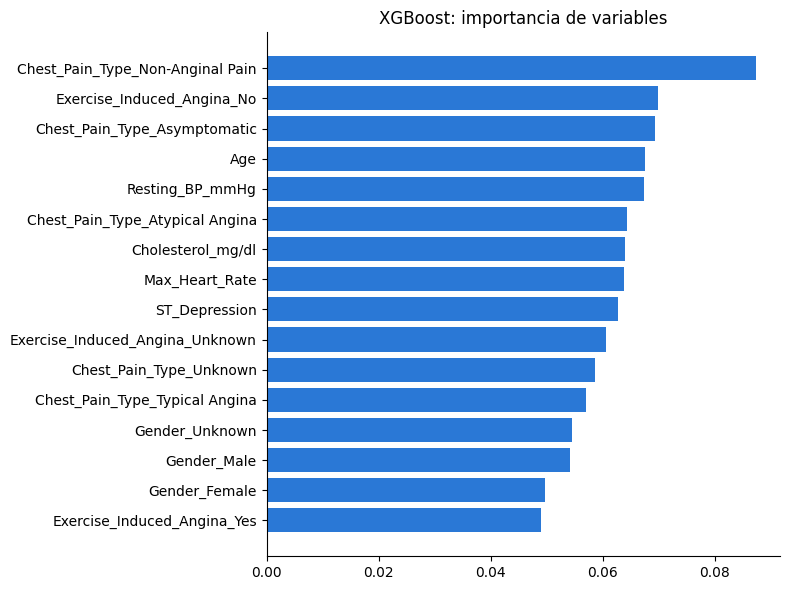

In [44]:
# 5.6 XGBoost (datos sin escalar y misma división que la regresión logística 1 y el random forest)
# Hiperparámetros conservadores fijados de antemano (sin mirar la prueba) para limitar el sobreajuste
from xgboost import XGBClassifier

modelo_xgb = XGBClassifier(
    n_estimators=200, max_depth=3, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=5, reg_lambda=1.0,
    eval_metric='logloss', random_state=42, n_jobs=-1
)
modelo_xgb.fit(X_train, y_train)

y_pred_xgb = modelo_xgb.predict(X_test)
y_prob_xgb = modelo_xgb.predict_proba(X_test)[:, 1]

print("XGBoost entrenado con", X_train.shape[0], "pacientes y", X_train.shape[1], "variables")
print("\nMétricas en la prueba (XGBoost):")
print(pd.Series(metricas(y_test, y_pred_xgb, y_prob_xgb)).round(3).to_string())

print("\nAUC-ROC entrenamiento vs prueba:",
      round(roc_auc_score(y_train, modelo_xgb.predict_proba(X_train)[:, 1]), 3),
      "vs", round(roc_auc_score(y_test, y_prob_xgb), 3))

imp_xgb = pd.Series(modelo_xgb.feature_importances_, index=X_train.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp_xgb.index, imp_xgb.values, color='#2a78d6')
ax.set_title('XGBoost: importancia de variables')
sns.despine()
plt.tight_layout(); plt.show()

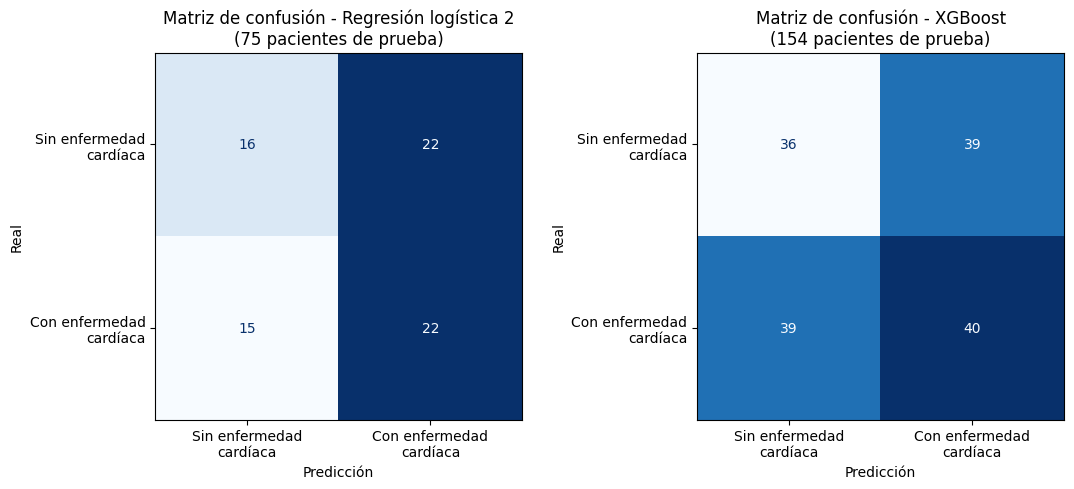

In [45]:
# Matrices de confusión: regresión logística 2 y XGBoost (cada una sobre su conjunto de prueba)
etiquetas_cm = ['Sin enfermedad\ncardíaca', 'Con enfermedad\ncardíaca']

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (nombre, y_real, y_pred) in zip(axes, [
        ('Regresión logística 2\n(75 pacientes de prueba)', y2_test, y_pred_lr2),
        ('XGBoost\n(154 pacientes de prueba)', y_test, y_pred_xgb)]):
    ConfusionMatrixDisplay(confusion_matrix(y_real, y_pred), display_labels=etiquetas_cm).plot(
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Matriz de confusión - {nombre}')
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Real')
plt.tight_layout(); plt.show()

## 5.7 Comparación de modelos

In [46]:
# 5.7 Comparación de los cuatro modelos
# La regresión logística 2 se evalúa en una prueba distinta (muestra reducida), así que no es una comparación directa
modelos = {
    'Regresión logística 1 (con Unknown)': (y_test, y_pred_lr, y_prob_lr, roc_auc_score(y_train, modelo_lr.predict_proba(X_train_esc)[:, 1])),
    'Regresión logística 2 (sin Unknown)': (y2_test, y_pred_lr2, y_prob_lr2, roc_auc_score(y2_train, modelo_lr2.predict_proba(X2_train_esc)[:, 1])),
    'Random forest': (y_test, y_pred_rf, y_prob_rf, roc_auc_score(y_train, modelo_rf.predict_proba(X_train)[:, 1])),
    'XGBoost': (y_test, y_pred_xgb, y_prob_xgb, roc_auc_score(y_train, modelo_xgb.predict_proba(X_train)[:, 1])),
}

filas = {}
for nombre, (y_real, y_pred, y_prob, auc_train) in modelos.items():
    m = metricas(y_real, y_pred, y_prob)
    m['AUC-ROC (entrenamiento)'] = auc_train
    m['Pacientes en prueba'] = len(y_real)
    filas[nombre] = m

tabla_final = pd.DataFrame(filas).T
tabla_final['Pacientes en prueba'] = tabla_final['Pacientes en prueba'].astype(int)
print(tabla_final.round(3).to_string())

                                     Accuracy  Precision  Recall     F1  AUC-ROC  AUC-ROC (entrenamiento)  Pacientes en prueba
Regresión logística 1 (con Unknown)     0.494      0.506   0.570  0.536    0.475                    0.587                  154
Regresión logística 2 (sin Unknown)     0.507      0.500   0.595  0.543    0.517                    0.605                   75
Random forest                           0.494      0.506   0.570  0.536    0.482                    0.849                  154
XGBoost                                 0.494      0.506   0.506  0.506    0.506                    0.900                  154


## 5.8 XGBoost ajustado (búsqueda de hiperparámetros)

Se buscan los hiperparámetros de XGBoost con `RandomizedSearchCV` (50 combinaciones al azar) y validación cruzada estratificada de 5 particiones, usando **solo el conjunto de entrenamiento** y AUC-ROC como criterio. El conjunto de prueba se usa una única vez, al final, con el mejor modelo encontrado.

In [47]:
# 5.8 XGBoost ajustado: búsqueda aleatoria + validación cruzada (solo con el conjunto de entrenamiento)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_score

param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'max_depth': [2, 3, 4],
    'min_child_weight': [1, 5, 10, 20],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'reg_lambda': [1, 5, 10],
    'gamma': [0, 1, 5],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

busqueda = RandomizedSearchCV(
    XGBClassifier(eval_metric='logloss', random_state=42, n_jobs=-1),
    param_distributions=param_dist, n_iter=50,
    scoring='roc_auc', cv=cv, random_state=42, n_jobs=-1
)
busqueda.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda.best_params_)
print("AUC-ROC en validación cruzada (mejor combinación):", round(busqueda.best_score_, 3))

# Referencia: el XGBoost de la sección 5.6 (valores fijos) evaluado con las mismas particiones
auc_cv_xgb = cross_val_score(modelo_xgb, X_train, y_train, cv=cv, scoring='roc_auc')
print("AUC-ROC en validación cruzada (XGBoost 5.6, valores fijos):", round(auc_cv_xgb.mean(), 3), "+/-", round(auc_cv_xgb.std(), 3))

# La prueba se usa una sola vez, con el mejor modelo
modelo_xgb2 = busqueda.best_estimator_
y_pred_xgb2 = modelo_xgb2.predict(X_test)
y_prob_xgb2 = modelo_xgb2.predict_proba(X_test)[:, 1]

print("\nAUC-ROC entrenamiento vs prueba (XGBoost ajustado):",
      round(roc_auc_score(y_train, modelo_xgb2.predict_proba(X_train)[:, 1]), 3),
      "vs", round(roc_auc_score(y_test, y_prob_xgb2), 3))

tabla_58 = pd.DataFrame({
    'Regresión logística 1': metricas(y_test, y_pred_lr, y_prob_lr),
    'Random forest': metricas(y_test, y_pred_rf, y_prob_rf),
    'XGBoost (valores fijos)': metricas(y_test, y_pred_xgb, y_prob_xgb),
    'XGBoost ajustado': metricas(y_test, y_pred_xgb2, y_prob_xgb2),
}).T.round(3)
print("\nMétricas en el conjunto de prueba (154 pacientes):")
print(tabla_58.to_string())

Mejores hiperparámetros: {'subsample': 0.6, 'reg_lambda': 5, 'n_estimators': 200, 'min_child_weight': 10, 'max_depth': 4, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.8}
AUC-ROC en validación cruzada (mejor combinación): 0.545
AUC-ROC en validación cruzada (XGBoost 5.6, valores fijos): 0.507 +/- 0.046

AUC-ROC entrenamiento vs prueba (XGBoost ajustado): 0.853 vs 0.494

Métricas en el conjunto de prueba (154 pacientes):
                         Accuracy  Precision  Recall     F1  AUC-ROC
Regresión logística 1       0.494      0.506   0.570  0.536    0.475
Random forest               0.494      0.506   0.570  0.536    0.482
XGBoost (valores fijos)     0.494      0.506   0.506  0.506    0.506
XGBoost ajustado            0.506      0.519   0.532  0.525    0.494


## 5.9 Comparación con validación cruzada repetida y prueba de permutación

Una sola división 80/20 da métricas muy ruidosas (154 pacientes de prueba), así que aquí se comparan los modelos con **validación cruzada estratificada repetida** (5 particiones × 3 repeticiones), usando AUC-ROC (media ± desviación estándar). La imputación y el escalado van dentro de un `Pipeline`, de modo que se ajustan solo con el entrenamiento de cada partición. Además, una **prueba de permutación** (100 barajadas aleatorias de las etiquetas) comprueba si el AUC-ROC real supera al que se obtiene cuando no existe ninguna relación entre las variables y la enfermedad.

AUC-ROC en validación cruzada repetida (5 particiones x 3 repeticiones):
                                                  AUC-ROC (media)  Desviación estándar
Referencia (azar)                                           0.500                0.000
Reg. logística, Unknown como categoría (769)                0.505                0.036
Reg. logística, Unknown imputado con moda (769)             0.517                0.043
Reg. logística, solo pacientes sin Unknown (375)            0.538                0.056
Random forest, Unknown como categoría (769)                 0.531                0.038
XGBoost, Unknown como categoría (769)                       0.514                0.035


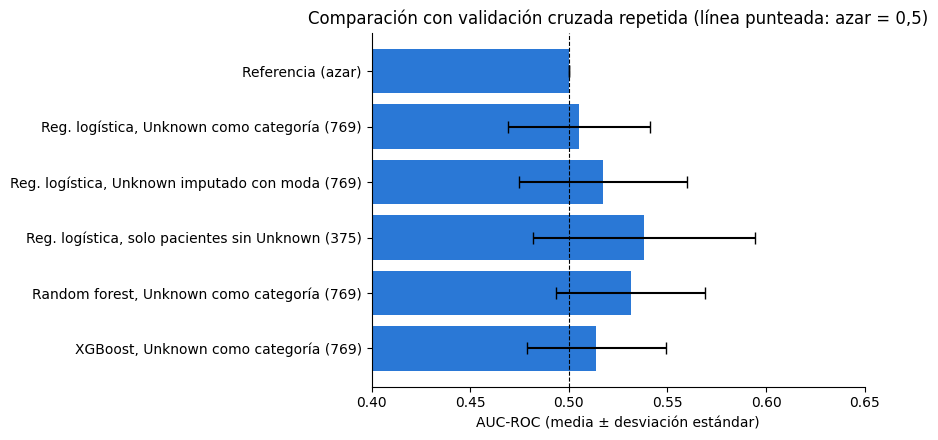


Prueba de permutación (100 barajadas de las etiquetas): ¿hay señal real?
Reg. logística, Unknown como categoría (769): AUC-ROC real 0.500 | con etiquetas barajadas 0.496 (percentil 95: 0.532) | p-valor 0.495
Reg. logística, Unknown imputado con moda (769): AUC-ROC real 0.521 | con etiquetas barajadas 0.494 (percentil 95: 0.534) | p-valor 0.208


In [48]:
# 5.9 Validación cruzada repetida + prueba de permutación
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_score, permutation_test_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier

cat_cols = ['Gender', 'Chest_Pain_Type', 'Exercise_Induced_Angina']

X_cv = df.drop(columns=['Patient_ID', 'Heart_Disease']).copy()
X_cv['Age'] = X_cv['Age'].astype(int)
y_cv = df['Heart_Disease'].astype(int)

# Versión con 'Unknown' devuelto a nulo (para imputarlo dentro del Pipeline)
X_cv_nan = X_cv.copy()
X_cv_nan[cat_cols] = X_cv_nan[cat_cols].replace('Unknown', np.nan)
sin_unk = X_cv_nan[cat_cols].notna().all(axis=1).values

prep_unk = ColumnTransformer([('num', StandardScaler(), cols_numericas),
                              ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
prep_moda = ColumnTransformer([('num', StandardScaler(), cols_numericas),
                               ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                                                 ('ohe', OneHotEncoder(handle_unknown='ignore'))]), cat_cols)])

xgb_fijo = dict(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                min_child_weight=5, eval_metric='logloss', random_state=42, n_jobs=-1)
rf_fijo = dict(n_estimators=300, max_depth=5, min_samples_leaf=10, random_state=42, n_jobs=-1)

candidatos = {
    'Referencia (azar)': (Pipeline([('p', prep_unk), ('m', DummyClassifier(strategy='prior'))]), X_cv, y_cv),
    'Reg. logística, Unknown como categoría (769)': (Pipeline([('p', prep_unk), ('m', LogisticRegression(max_iter=1000))]), X_cv, y_cv),
    'Reg. logística, Unknown imputado con moda (769)': (Pipeline([('p', prep_moda), ('m', LogisticRegression(max_iter=1000))]), X_cv_nan, y_cv),
    'Reg. logística, solo pacientes sin Unknown (375)': (Pipeline([('p', prep_unk), ('m', LogisticRegression(max_iter=1000))]), X_cv[sin_unk], y_cv[sin_unk]),
    'Random forest, Unknown como categoría (769)': (Pipeline([('p', prep_unk), ('m', RandomForestClassifier(**rf_fijo))]), X_cv, y_cv),
    'XGBoost, Unknown como categoría (769)': (Pipeline([('p', prep_unk), ('m', XGBClassifier(**xgb_fijo))]), X_cv, y_cv),
}

cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
res_cv = {}
for nombre, (pipe, XX, yy) in candidatos.items():
    s = cross_val_score(pipe, XX, yy, cv=cv_rep, scoring='roc_auc')
    res_cv[nombre] = (s.mean(), s.std())

tabla_cv = pd.DataFrame(res_cv, index=['AUC-ROC (media)', 'Desviación estándar']).T.round(3)
print("AUC-ROC en validación cruzada repetida (5 particiones x 3 repeticiones):")
print(tabla_cv.to_string())

fig, ax = plt.subplots(figsize=(9, 4.5))
nombres = list(res_cv.keys())[::-1]
ax.barh(nombres, [res_cv[n][0] for n in nombres], xerr=[res_cv[n][1] for n in nombres], color='#2a78d6', capsize=4)
ax.axvline(0.5, color='black', linestyle='--', linewidth=0.8)
ax.set_xlim(0.4, 0.65)
ax.set_xlabel('AUC-ROC (media ± desviación estándar)')
ax.set_title('Comparación con validación cruzada repetida (línea punteada: azar = 0,5)')
sns.despine()
plt.tight_layout(); plt.show()

print("\nPrueba de permutación (100 barajadas de las etiquetas): ¿hay señal real?")
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for nombre in ['Reg. logística, Unknown como categoría (769)', 'Reg. logística, Unknown imputado con moda (769)']:
    pipe, XX, yy = candidatos[nombre]
    real, perm, pval = permutation_test_score(pipe, XX, yy, scoring='roc_auc', cv=cv5,
                                              n_permutations=100, random_state=42, n_jobs=-1)
    print(f"{nombre}: AUC-ROC real {real:.3f} | con etiquetas barajadas {perm.mean():.3f} (percentil 95: {np.percentile(perm, 95):.3f}) | p-valor {pval:.3f}")

# **Parte 6: Evaluación**

---

## 6.1 Métricas utilizadas

Los modelos se evaluaron en el conjunto de prueba (154 pacientes que no se usaron para entrenar) con estas métricas. La regresión logística 2 se entrenó sin los pacientes con "Unknown", por lo que se evaluó en su propia prueba reducida (75 pacientes):

- **Accuracy (exactitud):** proporción de pacientes clasificados correctamente.
- **Precision:** de los pacientes que el modelo marca con enfermedad, cuántos realmente la tienen.
- **Recall (sensibilidad):** de los pacientes que sí tienen enfermedad, cuántos detecta el modelo. Es la métrica principal de la pregunta de investigación, porque en un contexto clínico no detectar a un paciente enfermo (falso negativo) es más grave que una falsa alarma.
- **F1:** promedio equilibrado entre precision y recall.
- **AUC-ROC:** capacidad del modelo para ordenar a los pacientes según su riesgo; 0,5 equivale al azar y 1,0 a una separación perfecta.
- **Matriz de confusión:** cantidad de aciertos y de errores de cada tipo (falsos positivos y falsos negativos).
- **Referencia:** un modelo ingenuo que predice "enfermo" a todos los pacientes; sirve para saber si los modelos realmente aportan algo.
- **AUC-ROC en entrenamiento y en prueba:** se comparan para detectar sobreajuste.
- **Validación cruzada (5 particiones):** se aplicó a la regresión logística 2, para tener una medida más estable que la de una prueba de 75 pacientes, y a la búsqueda de hiperparámetros del XGBoost ajustado.
- **Validación cruzada repetida y prueba de permutación:** comparan todos los modelos con las mismas particiones (AUC-ROC como media ± desviación estándar) y comprueban si el AUC-ROC real supera al que se obtiene al barajar al azar las etiquetas (sección 5.9).

## 6.2 Interpretación de resultados

| Modelo | Pacientes en prueba | Accuracy | Precision | Recall | F1 | AUC-ROC |
|---|---|---|---|---|---|---|
| Regresión logística 1 (con Unknown) | 154 | 0,494 | 0,506 | 0,570 | 0,536 | 0,475 |
| Random forest | 154 | 0,494 | 0,506 | 0,570 | 0,536 | 0,482 |
| XGBoost | 154 | 0,494 | 0,506 | 0,506 | 0,506 | 0,506 |
| XGBoost ajustado | 154 | 0,506 | 0,519 | 0,532 | 0,525 | 0,494 |
| Referencia (predice "enfermo" a todos) | 154 | 0,513 | 0,513 | 1,000 | 0,678 | 0,500 |
| Regresión logística 2 (sin Unknown) | 75 | 0,507 | 0,500 | 0,595 | 0,543 | 0,517 |
| Referencia de la prueba reducida | 75 | 0,493 | 0,493 | 1,000 | 0,661 | 0,500 |

La regresión logística 2 se evalúa en una prueba distinta, por eso va en filas aparte con su propia referencia: sus métricas no son directamente comparables con las de los demás modelos.

- **Todos los modelos rinden casi como el azar.** La regresión logística 1, el random forest y XGBoost aciertan 76 de 154 pacientes y el XGBoost ajustado 78, contra 79 de la referencia; la regresión logística 2 acierta 38 de 75, contra 37 de su referencia. El margen de error del accuracy es de ≈ ±8 puntos con 154 pacientes y de ≈ ±11 con 75, así que ninguna de estas diferencias se distingue del azar.
- **El recall no es un buen resultado aquí.** La regresión logística 1 y el random forest detectan a 45 de los 79 pacientes enfermos (≈ 57 %), pero también marcan como enfermos a 44 de los 75 sanos (59 %). La regresión logística 2 detecta a 22 de 37 enfermos (≈ 59 %) y marca como enfermos a 22 de 38 sanos (≈ 58 %). XGBoost detecta a 40 de 79 (≈ 51 %) y da falsa alarma a 39 de 75 sanos (52 %). El XGBoost ajustado detecta a 42 de 79 (≈ 53 %) y también da falsa alarma a 39 de 75 sanos (52 %). En todos los casos detectan a los enfermos casi con la misma frecuencia con la que dan falsas alarmas a los sanos. La referencia llega a un recall de 1,0 sin ningún criterio, por eso el recall solo se interpreta junto con la precision (entre 0,50 y 0,52 en todos los modelos, cerca de la proporción de enfermos, ≈ 0,51).
- **AUC-ROC cerca de 0,5 en todos los modelos:** 0,475 (regresión logística 1), 0,482 (random forest), 0,506 (XGBoost), 0,494 (XGBoost ajustado) y 0,517 (regresión logística 2). Ninguno ordena a los pacientes por riesgo mejor que el azar; que algunos queden un poco por debajo o por encima de 0,5 es ruido, no una señal. En la validación cruzada de la regresión logística 2 el AUC-ROC es 0,548 ± 0,08: algo por encima de 0,5, pero la ventaja es del mismo tamaño que la variación entre particiones, así que no es evidencia clara de señal.
- **Quitar los "Unknown" no mejoró el modelo de forma demostrable.** La regresión logística 2 sube unas décimas en las métricas, pero entrena con 300 pacientes en lugar de 615 y se evalúa con solo 75, de modo que la diferencia frente a la regresión logística 1 no se distingue del ruido. Los valores "Unknown" no parecen ser la causa principal del bajo rendimiento, y eliminarlos costó más de la mitad de los pacientes (394 de 769).
- **El ajuste de hiperparámetros de XGBoost no mejoró la prueba.** Con 50 combinaciones al azar y validación cruzada de 5 particiones solo sobre el entrenamiento, la mejor (profundidad 4, tasa de aprendizaje 0,05, 200 árboles y hoja mínima 10) alcanzó un AUC-ROC de 0,545 en validación cruzada, contra 0,507 ± 0,046 del XGBoost de valores fijos; pero en la prueba dio 0,494 (y 0,853 en entrenamiento). Esa mejora en validación cruzada es optimista: es la mejor de 50 combinaciones y queda dentro de la variación entre particiones, es decir, la búsqueda se ajustó al ruido.
- **Sobreajuste del random forest y de XGBoost:** el random forest, aun limitando su profundidad (máximo 5) y el tamaño de hoja (mínimo 10), tiene un AUC-ROC de 0,85 en entrenamiento y 0,48 en prueba. XGBoost, con hiperparámetros conservadores (profundidad 3, tasa de aprendizaje 0,05 y submuestreo de 80 %), pasa de 0,90 en entrenamiento a 0,51 en prueba. Ambos se ajustan al ruido del entrenamiento sin aprender un patrón que generalice. Las regresiones logísticas se ajustan menos al entrenamiento (0,59 y 0,61) pero tampoco encuentran señal en prueba (0,48 y 0,52).
- **Importancia de variables:** en el random forest las 5 variables numéricas tienen importancias casi iguales (entre 0,15 y 0,18) y las categóricas entre 0,01 y 0,02. En la regresión logística 2 los coeficientes más grandes son el dolor torácico no anginoso (−0,45, baja la probabilidad de enfermedad), la angina típica (+0,24), la frecuencia cardíaca máxima (−0,22) y la edad (+0,21); el resto no pasa de 0,12 en valor absoluto. Estos efectos no son confiables: por ejemplo, la angina típica tiene un coeficiente positivo, pero en los 769 pacientes su tasa de enfermedad (48 %) está por debajo del promedio (51 %). Como los modelos no generalizan y los coeficientes son pequeños, estas importancias reflejan sobre todo ruido y no permiten señalar una variable determinante.
- **Validación cruzada repetida y prueba de permutación (sección 5.9).** Con 5 particiones × 3 repeticiones, el AUC-ROC (media ± desviación estándar) es 0,505 ± 0,036 para la regresión logística con "Unknown" como categoría, 0,517 ± 0,043 imputando los "Unknown" con la moda, 0,538 ± 0,056 usando solo los 375 pacientes sin "Unknown", 0,531 ± 0,038 para el random forest y 0,514 ± 0,035 para XGBoost. El orden va en el sentido de que los "Unknown" restan (el peor resultado es el de la regresión logística que los trata como categoría y el mejor el de la que solo usa pacientes sin ellos), pero todas las diferencias caben dentro de una desviación estándar, así que ningún modelo es mejor que otro. En la prueba de permutación (100 barajadas de las etiquetas), la regresión logística con "Unknown" como categoría obtiene un AUC-ROC de 0,500 contra 0,496 con etiquetas barajadas (p ≈ 0,5), y con los "Unknown" imputados con la moda 0,521 contra 0,494 (p ≈ 0,21): en ningún caso hay evidencia estadística de que estas variables contengan señal sobre la enfermedad.

## 6.3 Limitaciones del modelo

- **Pocos datos:** de 1020 registros quedaron 769 pacientes tras eliminar duplicados y pacientes sin diagnóstico (231); la prueba tiene solo 154, por lo que las métricas son poco estables. La regresión logística 2 quedó con apenas 375 pacientes (300 para entrenar y 75 para probar), así que sus métricas son aún más inestables.
- **Calidad de los datos:** entre 21 % y 23 % de valores desconocidos en sexo, tipo de dolor torácico y angina inducida (agrupados como "Unknown" en la regresión logística 1, el random forest y XGBoost, y eliminados en la regresión logística 2), nulos numéricos y valores atípicos reemplazados por la mediana, y etiquetas inconsistentes que hubo que corregir. Estas decisiones pueden haber ocultado o distorsionado información.
- **Imputación antes de dividir:** las medianas se calcularon con todos los pacientes antes de separar entrenamiento y prueba, lo que puede filtrar algo de información de la prueba hacia el entrenamiento. Afecta a ≈ 2 % de los valores, así que el efecto debería ser pequeño.
- **Una sola división y poco ajuste:** se evaluó con una única partición 80/20 y con hiperparámetros fijados de antemano (en el random forest, profundidad máxima 5 y hoja mínima 10; en XGBoost, 200 árboles, profundidad 3 y tasa de aprendizaje 0,05), sin búsqueda de mejores parámetros (salvo en el XGBoost ajustado, buscado con validación cruzada solo sobre el entrenamiento).
- **Comparación no directa de la regresión logística 2:** se evalúa en una prueba distinta (75 pacientes), por lo que sus métricas no se pueden comparar de forma directa con las de los demás modelos.
- **Pocas variables:** solo 8 variables clínicas y demográficas básicas; no incluyen otros factores relevantes, como antecedentes familiares, diabetes, tabaquismo o resultados de electrocardiograma. También es importante aclarar que no se toma el criterio del personal médico quien hace la valoración, como palidez o algún aspecto físico.
- **Uso clínico:** con estos resultados ninguno de los modelos es apto para apoyar decisiones médicas.

## 6.4 Posibles mejoras

- **Ajuste de hiperparámetros más riguroso:** el random forest y XGBoost se limitaron con valores fijos y aun así sobreajustan, y la búsqueda aleatoria de XGBoost (50 combinaciones) no mejoró la prueba. Falta ajustar el random forest y el parámetro C de la regresión logística, probar XGBoost con parada temprana y usar validación cruzada anidada para que la estimación de la búsqueda no sea optimista, eligiendo por recall o AUC-ROC.
- **Más pacientes y más variables clínicas**, y recuperar desde la fuente los valores desconocidos.
- **Mejor captura de datos:** listas cerradas para sexo y angina, rangos fisiológicos válidos y diagnóstico obligatorio al registrar.
- **Variables nuevas** (por ejemplo, combinaciones de variables) y ajustar el umbral de decisión para priorizar el recall; esto último solo tiene sentido si el modelo muestra señal (AUC-ROC claramente mayor a 0,5).

# **Parte 7: Conclusiones**

---

## ¿Se cumplió el objetivo?

**Parcialmente.** El objetivo de proceso se cumplió: se exploró el dataset, se limpiaron y prepararon los datos (duplicados, nulos, etiquetas, valores atípicos, codificación, división y escalado) y se entrenaron y evaluaron cinco modelos de clasificación: dos regresiones logísticas (con y sin los pacientes que tienen "Unknown"), random forest, XGBoost y XGBoost ajustado con búsqueda de hiperparámetros. El objetivo predictivo no: ninguno distinguió a los pacientes con y sin enfermedad por encima del azar (recall entre 0,51 y 0,60 y AUC-ROC entre 0,48 y 0,52 en la prueba, sin superar de forma clara el 0,5 del azar).

Respondiendo a la pregunta de investigación: con las variables clínicas básicas de este dataset no fue posible predecir la presencia de enfermedad cardíaca con un recall aceptable, ni siquiera retirando los pacientes con valores "Unknown" o probando un modelo más flexible como XGBoost (ni siquiera ajustando sus hiperparámetros), y ninguna variable destacó claramente sobre las demás. Esto no demuestra que estas variables no se relacionen con la enfermedad en general; indica que, en estos datos, la relación es muy débil: la prueba de permutación de la sección 5.9 ni siquiera permite distinguirla del azar. Una posible explicación, que estos datos no permiten confirmar, es que el dataset tenga poca señal real: varias medidas traen decimales poco habituales en registros clínicos (por ejemplo, una presión de 151,34 mmHg), lo que sugiere datos simulados.

## Hallazgos relevantes

- **Datos de baja calidad:** de 1020 registros se conservaron 769. Había 20 duplicados, ≈ 23 % de pacientes sin diagnóstico, entre 21 % y 23 % de valores desconocidos en las variables categóricas, etiquetas escritas de varias formas (por ejemplo, 4 variantes para el sexo y el diagnóstico mezclando números y texto) y valores fisiológicamente imposibles (colesterol de hasta 977 mg/dl y frecuencia cardíaca máxima de 297 lpm).
- **Clases balanceadas:** ≈ 51 % de los pacientes tiene enfermedad, así que no hizo falta ajustar el desbalance.
- **Rendimiento cercano al azar:** los modelos aciertan igual o menos que uno que marca a todos como enfermos (la regresión logística 2 solo supera por un paciente a su referencia en una prueba de 75), y el random forest y XGBoost sobreajustan (AUC-ROC de 0,85 y 0,90 en entrenamiento contra 0,48 y 0,51 en prueba, incluso limitando su complejidad); el XGBoost ajustado repite el patrón (0,85 contra 0,49).
- **Quitar los "Unknown" no cambió el resultado:** la regresión logística 2 (375 pacientes, sin "Unknown") obtuvo un AUC-ROC de 0,517 en la prueba y de 0,548 en validación cruzada, sin una diferencia que se distinga del ruido frente a la regresión logística 1 (0,475), y para lograrlo se eliminó a más de la mitad de los pacientes (394 de 769).
- **Ajustar los hiperparámetros de XGBoost no cambió el resultado:** la mejor de 50 combinaciones llegó a un AUC-ROC de 0,545 en validación cruzada (contra 0,507 con valores fijos), pero en la prueba dio 0,494. La mejora en validación cruzada es optimista y se explica por elegir la mejor entre muchas combinaciones sobre datos con poca señal.
- **No hay señal estadística en los datos:** en la prueba de permutación, el AUC-ROC real de la regresión logística (0,500 con "Unknown" como categoría y 0,521 imputándolos con la moda) no se distingue del que se obtiene con etiquetas barajadas (p ≈ 0,5 y p ≈ 0,21).
- **Ningún modelo es mejor que otro:** en validación cruzada repetida los modelos quedan entre 0,505 y 0,538 de AUC-ROC, dentro de una desviación estándar entre sí. Si hubiera que elegir uno para esta base, la regresión logística (con los "Unknown" imputados dentro de un `Pipeline`) es la opción más simple, interpretable y con menos sobreajuste (AUC-ROC de 0,59 en entrenamiento y 0,48 en prueba, contra 0,85 y 0,90 en entrenamiento del random forest y de XGBoost), aunque esa elección es de criterio y no de métricas.
- **Un recall de ≈ 0,6 puede engañar:** parece aceptable, pero un modelo que marca a todos como enfermos obtiene 1,0. Comparar contra una referencia y mirar la precision fue clave para interpretar bien los resultados.
- **Ninguna variable determinante:** las importancias del random forest son parejas y los coeficientes de las regresiones logísticas son pequeños; en la regresión logística 2 los mayores son el dolor torácico no anginoso (−0,45), la angina típica (+0,24), la frecuencia cardíaca máxima (−0,22) y la edad (+0,21), sin evidencia de que generalicen.

## Valor que aportaría a una organización

- **Un flujo reutilizable:** la preparación (limpieza, codificación, división y escalado) y la evaluación quedan documentadas y se pueden repetir cuando se disponga de mejores datos.
- **Un resultado negativo útil:** muestra con evidencia que, con cinco modelos distintos (lineales y de árboles, con y sin los pacientes con "Unknown" y con hiperparámetros ajustados) y estas 8 variables, no se justifica construir una herramienta de apoyo clínico, lo que evita invertir en ella y orienta a recolectar más pacientes y más variables antes de volver a intentarlo.
- **Evidencia del costo de la mala calidad de datos:** gran parte del esfuerzo fue corregir errores de registro, y los valores "Unknown" obligaron a elegir entre conservarlos como una categoría más o eliminar a más de la mitad de los pacientes. Estandarizar la captura (listas cerradas, rangos válidos y diagnóstico obligatorio) mejoraría cualquier análisis futuro.
- **Potencial a futuro:** con datos más completos y validación clínica, un modelo así podría apoyar la priorización de pacientes, siempre como apoyo a la decisión médica y nunca como reemplazo del diagnóstico.

# **Parte 8: Ejemplo con nuevos datos**

---



In [55]:
# Un nuevo paciente

nuevo = pd.DataFrame([{"Age": 81, "Gender": "Male", "Chest_Pain_Type": "Typical Angina",
                       "Resting_BP_mmHg": 120, "Cholesterol_mg/dl": 175, "Max_Heart_Rate": 96,
                       "ST_Depression": -0.9, "Exercise_Induced_Angina": "Yes"}])

In [56]:
# Predicción del nuevo paciente con los cinco modelos
# El paciente se prepara igual que los datos de entrenamiento: one-hot con las mismas columnas y mismo orden,
# y escalado de las numéricas con el scaler ajustado en entrenamiento (no se vuelve a ajustar).
cols_categoricas = ['Gender', 'Chest_Pain_Type', 'Exercise_Induced_Angina']

nuevo_cod = pd.get_dummies(nuevo, columns=cols_categoricas, dtype=int)
nuevo_cod = nuevo_cod.reindex(columns=X_train.columns, fill_value=0) # categorías que no aparecen quedan en 0

nuevo_esc = nuevo_cod.copy()
nuevo_esc[cols_numericas] = scaler.transform(nuevo_cod[cols_numericas])

# Regresión logística 2 (sin Unknown): usa las columnas de X2_train (sin las *_Unknown) y su propio escalador (scaler2)
nuevo_cod2 = nuevo_cod.reindex(columns=X2_train.columns, fill_value=0)
nuevo_esc2 = nuevo_cod2.copy()
nuevo_esc2[cols_numericas] = scaler2.transform(nuevo_cod2[cols_numericas])

# Probabilidad de enfermedad (clase 1) según cada modelo
prob_lr = modelo_lr.predict_proba(nuevo_esc)[0, 1]     # regresión logística 1: datos escalados
prob_lr2 = modelo_lr2.predict_proba(nuevo_esc2)[0, 1]  # regresión logística 2: datos escalados, sin Unknown
prob_rf = modelo_rf.predict_proba(nuevo_cod)[0, 1]     # random forest: datos sin escalar
prob_xgb = modelo_xgb.predict_proba(nuevo_cod)[0, 1]   # XGBoost: datos sin escalar
prob_xgb2 = modelo_xgb2.predict_proba(nuevo_cod)[0, 1] # XGBoost ajustado: datos sin escalar

print("Paciente evaluado:")
print(nuevo.T.rename(columns={0: 'Valor'}).to_string())
print()
for nombre, prob in [('Regresión logística 1', prob_lr), ('Regresión logística 2', prob_lr2),
                     ('Random forest', prob_rf), ('XGBoost', prob_xgb), ('XGBoost ajustado', prob_xgb2)]:
    resultado = 'CON enfermedad cardíaca' if prob >= 0.5 else 'SIN enfermedad cardíaca'
    print(f"{nombre}: probabilidad de enfermedad = {prob:.1%} -> predicción: {resultado}")

print()
print("Aviso: en la evaluación los cinco modelos rindieron como el azar (AUC-ROC de 0.475, 0.517, 0.482, 0.506 y 0.494, sin superar de forma clara el 0.5),")
print("por lo que esta predicción es solo un ejemplo del funcionamiento y no tiene valor diagnóstico.")

Paciente evaluado:
                                  Valor
Age                                  81
Gender                             Male
Chest_Pain_Type          Typical Angina
Resting_BP_mmHg                     120
Cholesterol_mg/dl                   175
Max_Heart_Rate                       96
ST_Depression                      -0.9
Exercise_Induced_Angina             Yes

Regresión logística 1: probabilidad de enfermedad = 60.4% -> predicción: CON enfermedad cardíaca
Regresión logística 2: probabilidad de enfermedad = 72.6% -> predicción: CON enfermedad cardíaca
Random forest: probabilidad de enfermedad = 64.8% -> predicción: CON enfermedad cardíaca
XGBoost: probabilidad de enfermedad = 71.5% -> predicción: CON enfermedad cardíaca
XGBoost ajustado: probabilidad de enfermedad = 56.7% -> predicción: CON enfermedad cardíaca

Aviso: en la evaluación los cinco modelos rindieron como el azar (AUC-ROC de 0.475, 0.517, 0.482, 0.506 y 0.494, sin superar de forma clara el 0.5),
por lo que e